# Social Media Risk Classification

## Imports & Settings


In [ ]:
!pip install shap imblearn

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
    GridSearchCV, cross_validate
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')


In [ ]:
SEED = 42
np.random.seed(SEED)

BSMAS_CUTOFF = 19

CLASS_NAMES = ['Not at-risk', 'At-risk']
PALETTE = ['#2196F3', '#F44336']
PLATFORM_COLORS = ['#FF7043', '#1976D2', '#E91E63', '#00BCD4', '#FFCA28', '#4CAF50', '#9C27B0']

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})


## Load & Clean Data

In [ ]:
data = pd.read_excel('/content/social media addiction 14_10_22.xlsx')
print(data.info())

In [ ]:

drop_cols = [c for c in data.columns if c.startswith('Unnamed')]
data_dropped = data.drop(columns=drop_cols, errors='ignore')
data_dropped.rename(columns={'Type of social media: Whatsapp': 'Whatsapp'}, inplace=True)

print('before cleaning:', data.shape)
print('after cleaning :', data_dropped.shape)


before cleaning: (258, 43)
after cleaning : (258, 25)


In [ ]:
features = ['Sex', 'Age', 'School failure', 'Whatsapp', 'Facebook', 'Instagram',
            'Twitter', 'Snapchat', 'TikTok', 'Other social',
            'Time spent on social media', 'Daily use of social media',
            'Which device', "Time's flow", 'Perceived anxiety during SM use',
            'Perceived loneliness ', 'SM checking', 'Video-games and online play',
            'Time spent on line playng videogames', 'BSMAS', 'RSES', 'CSIQ-A',
            ' STAI Y-1', 'STAI Y-2']

df = data_dropped[features].copy()
print(df.shape)
df.head()


(258, 24)


,Sex,Age,School failure,Whatsapp,Facebook,Instagram,Twitter,Snapchat,TikTok,Other social,...,Perceived anxiety during SM use,Perceived loneliness,SM checking,Video-games and online play,Time spent on line playng videogames,BSMAS,RSES,CSIQ-A,STAI Y-1,STAI Y-2
0,2,18,0,1,0,1,0,0,1,0,...,1,1,1,3,3,16,26,23,50,53
1,2,19,1,1,1,1,0,0,0,0,...,1,1,1,1,3,9,13,29,44,46
2,1,18,0,1,0,1,0,0,0,0,...,1,1,0,2,2,21,18,16,37,40
3,1,17,1,1,1,1,0,0,1,0,...,1,1,2,1,3,12,19,25,39,50
4,1,17,0,1,0,1,0,0,0,0,...,0,0,1,4,5,11,18,19,42,48


## Data Cleaning


In [ ]:
print(df.isnull().sum())


Sex                                     0
Age                                     0
School failure                          0
Whatsapp                                0
Facebook                                0
Instagram                               0
Twitter                                 0
Snapchat                                0
TikTok                                  0
Other social                            0
Time spent on social media              0
Daily use of social media               0
Which device                            0
Time's flow                             0
Perceived anxiety during SM use         0
Perceived loneliness                    0
SM checking                             0
Video-games and online play             0
Time spent on line playng videogames    0
BSMAS                                   0
RSES                                    0
CSIQ-A                                  0
 STAI Y-1                               0
STAI Y-2                          

## BSMAS Score Distribution


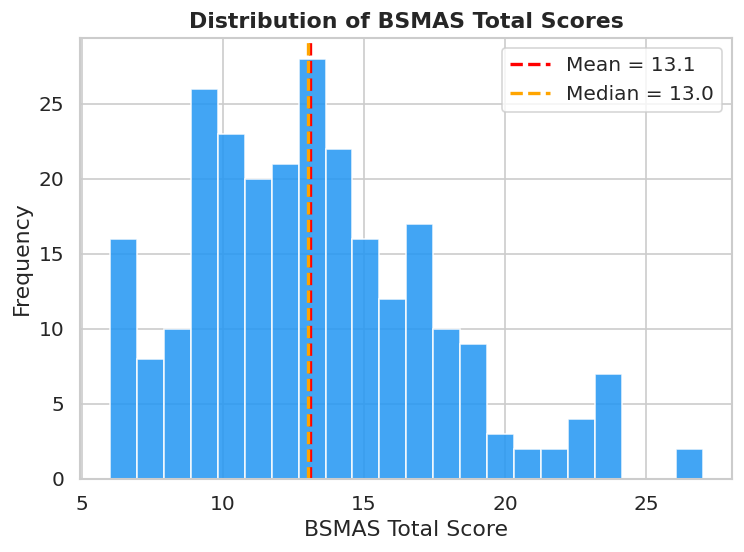

In [ ]:
plt.hist(
    df['BSMAS'],
    bins=22,
    color='#2196F3',
    edgecolor='white',
    alpha=0.85
)

plt.axvline(
    df['BSMAS'].mean(),
    color='red',
    linestyle='--',
    linewidth=2,
    label=f"Mean = {df['BSMAS'].mean():.1f}"
)

plt.axvline(
    df['BSMAS'].median(),
    color='orange',
    linestyle='--',
    linewidth=2,
    label=f"Median = {df['BSMAS'].median():.1f}"
)

plt.title('Distribution of BSMAS Total Scores', fontweight='bold')
plt.xlabel('BSMAS Total Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()


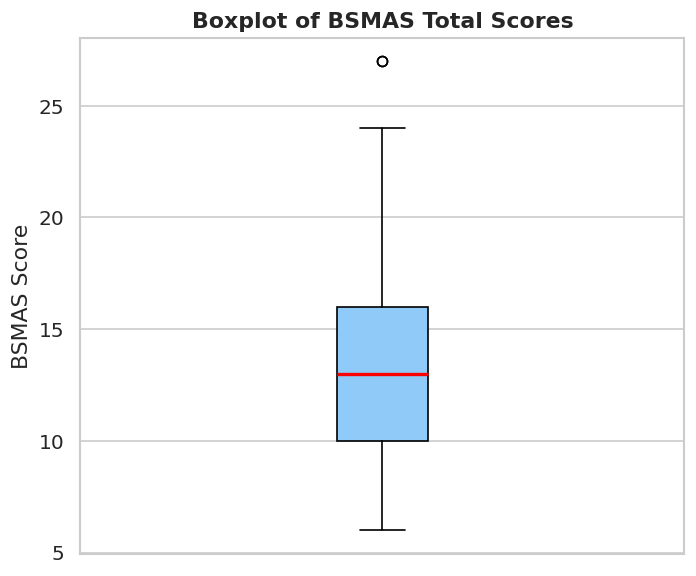

In [ ]:
plt.figure(figsize=(6, 5))

plt.boxplot(
    df['BSMAS'],
    patch_artist=True,
    boxprops=dict(facecolor='#90CAF9'),
    medianprops=dict(color='red', linewidth=2)
)

plt.title('Boxplot of BSMAS Total Scores', fontweight='bold')
plt.ylabel('BSMAS Score')
plt.xticks([])
plt.tight_layout()
plt.show()


In [ ]:
print(f"Mean     : {df['BSMAS'].mean():.2f}")
print(f"Median   : {df['BSMAS'].median():.2f}")
print(f"Std Dev  : {df['BSMAS'].std():.2f}")
print(f"Min      : {df['BSMAS'].min()}")
print(f"Max      : {df['BSMAS'].max()}")


Mean     : 13.07
Median   : 13.00
Std Dev  : 4.48
Min      : 6
Max      : 27


## Demographic Overview


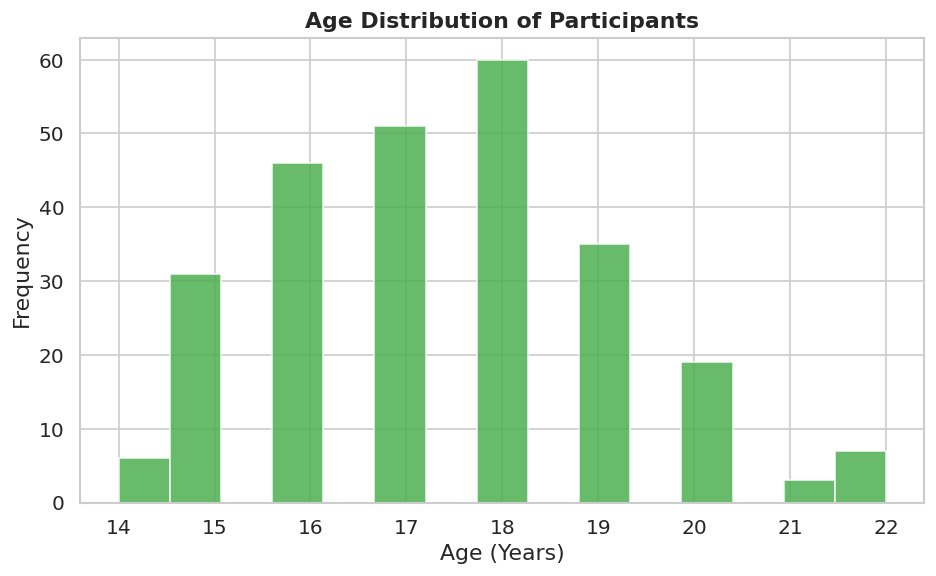

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df['Age'],
    bins=15,
    color='#4CAF50',
    edgecolor='white',
    alpha=0.85
)

plt.title('Age Distribution of Participants', fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


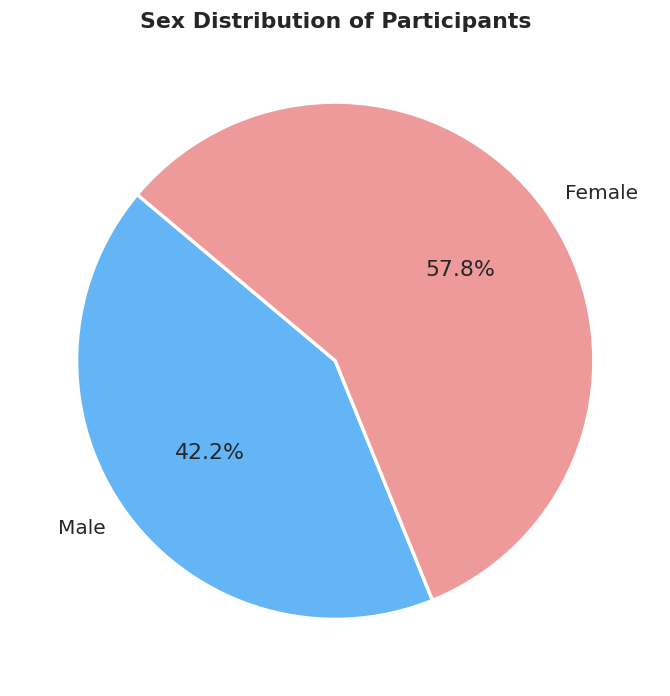

In [ ]:
sex_counts = df['Sex'].value_counts().sort_index()

plt.figure(figsize=(6, 6))

plt.pie(
    [sex_counts.get(1, 0), sex_counts.get(2, 0)],
    labels=['Male', 'Female'],
    colors=['#64B5F6', '#EF9A9A'],
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)

plt.title('Sex Distribution of Participants', fontweight='bold')

plt.tight_layout()
plt.show()


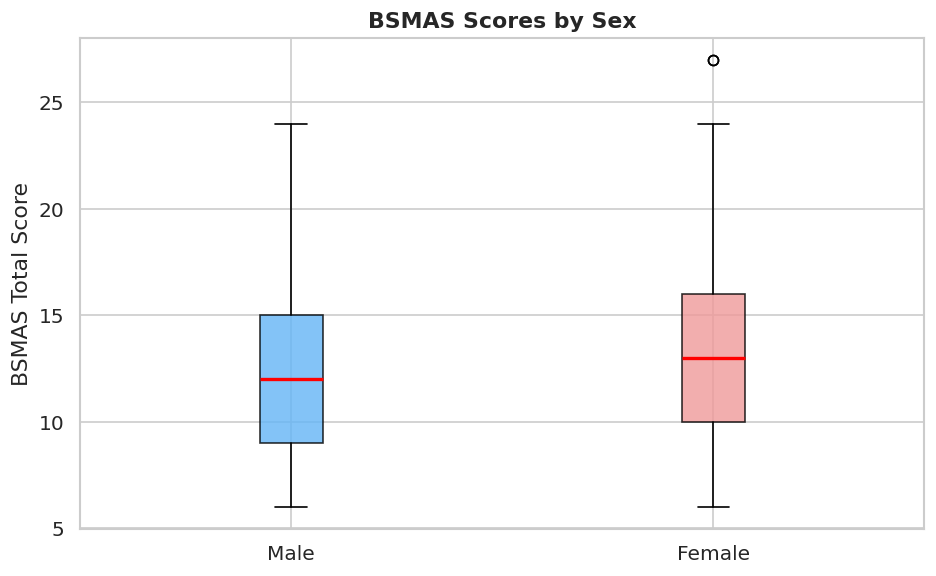

In [ ]:
male_b = df[df['Sex'] == 1]['BSMAS']
female_b = df[df['Sex'] == 2]['BSMAS']

plt.figure(figsize=(8, 5))

bp = plt.boxplot(
    [male_b, female_b],
    labels=['Male', 'Female'],
    patch_artist=True,
    medianprops=dict(color='red', linewidth=2)
)

for patch, color in zip(bp['boxes'], ['#64B5F6', '#EF9A9A']):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

plt.title('BSMAS Scores by Sex', fontweight='bold')
plt.ylabel('BSMAS Total Score')

plt.tight_layout()
plt.show()


In [ ]:
print(f"Sample Size: {len(df)}")
print(f"Mean Age: {df['Age'].mean():.2f}")
print(f"Age SD: {df['Age'].std():.2f}")
print(f"Minimum Age: {df['Age'].min()}")
print(f"Maximum Age: {df['Age'].max()}")

print("Sex Distribution")
print(sex_counts)


Sample Size: 258
Mean Age: 17.42
Age SD: 1.73
Minimum Age: 14
Maximum Age: 22
Sex Distribution
Sex
1    109
2    149
Name: count, dtype: int64


## Social Media Platform Usage


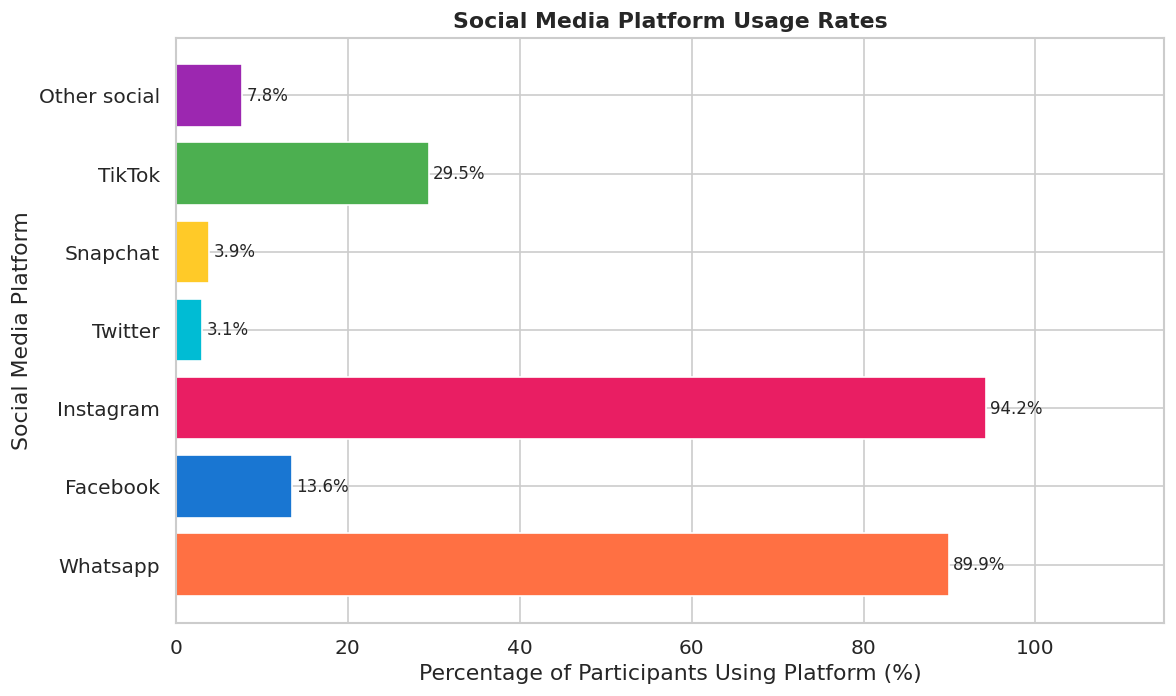

In [ ]:
platform_cols = [
    'Whatsapp', 'Facebook', 'Instagram',
    'Twitter', 'Snapchat', 'TikTok', 'Other social'
]

platform_pct = df[platform_cols].mean() * 100

plt.figure(figsize=(10, 6))

bars = plt.barh(
    platform_cols,
    platform_pct,
    color=PLATFORM_COLORS,
    edgecolor='white'
)

for bar, val in zip(bars, platform_pct):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height()/2,
        f'{val:.1f}%',
        va='center',
        fontsize=10
    )

plt.xlim(0, 115)
plt.xlabel('Percentage of Participants Using Platform (%)')
plt.ylabel('Social Media Platform')
plt.title('Social Media Platform Usage Rates', fontweight='bold')

plt.tight_layout()
plt.show()


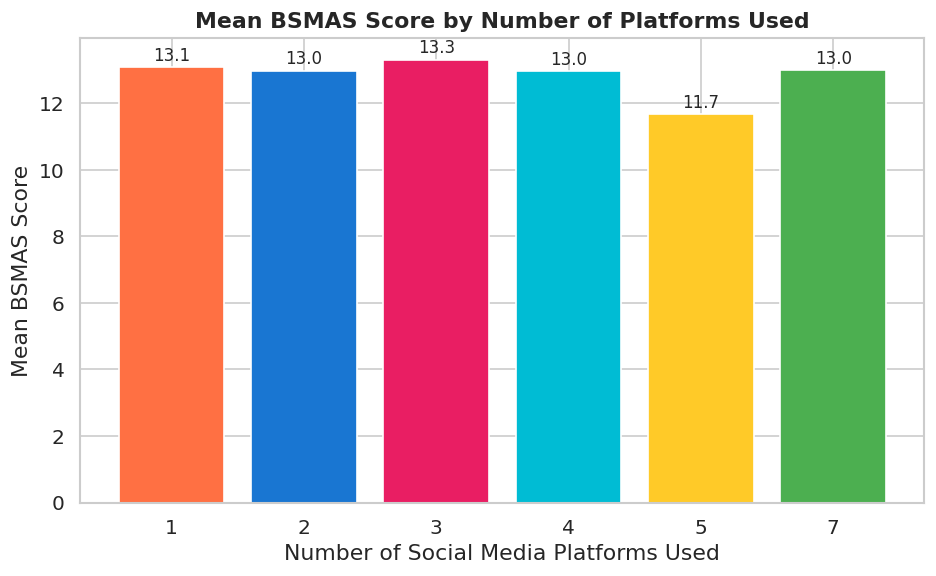

In [ ]:
df_tmp = df.copy()
df_tmp['n_platforms'] = df_tmp[platform_cols].sum(axis=1)

bsmas_by_plat = (
    df_tmp.groupby('n_platforms')['BSMAS']
    .mean()
    .sort_index()
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    bsmas_by_plat.index.astype(str),
    bsmas_by_plat.values,
    color=PLATFORM_COLORS,
    edgecolor='white'
)

for i, val in enumerate(bsmas_by_plat.values):
    plt.text(
        i,
        val + 0.2,
        f'{val:.1f}',
        ha='center',
        fontsize=10
    )

plt.xlabel('Number of Social Media Platforms Used')
plt.ylabel('Mean BSMAS Score')
plt.title('Mean BSMAS Score by Number of Platforms Used', fontweight='bold')

plt.tight_layout()
plt.show()


## Target: Binary "At-Risk" Classification

Class distribution (cut-off = BSMAS >= 19):
  Not at-risk : 229  (88.8%)
  At-risk     :  29  (11.2%)


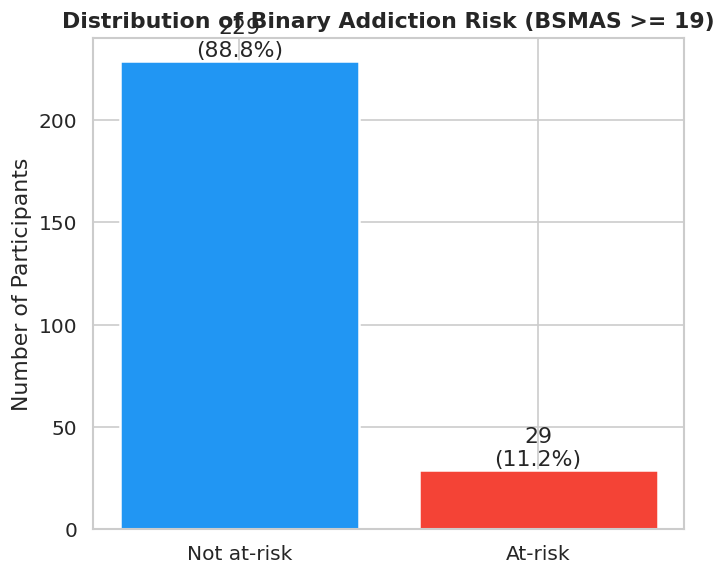

In [ ]:
df['addiction_risk'] = (df['BSMAS'] >= BSMAS_CUTOFF).astype(int)

vc = df['addiction_risk'].value_counts().sort_index()
print(f"Class distribution (cut-off = BSMAS >= {BSMAS_CUTOFF}):")
for cls, cnt in zip(CLASS_NAMES, vc):
    print(f"  {cls:12s}: {cnt:3d}  ({cnt/len(df)*100:.1f}%)")

plt.figure(figsize=(6, 5))
bars = plt.bar(CLASS_NAMES, vc, color=PALETTE, edgecolor='white', linewidth=1.5)
for bar, cnt in zip(bars, vc):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2,
              f'{cnt}\n({cnt/len(df)*100:.1f}%)', ha='center')
plt.title('Distribution of Binary Addiction Risk (BSMAS >= %d)' % BSMAS_CUTOFF, fontweight='bold')
plt.ylabel('Number of Participants')
plt.tight_layout()
plt.show()


## Psychometric Variables by Risk Group


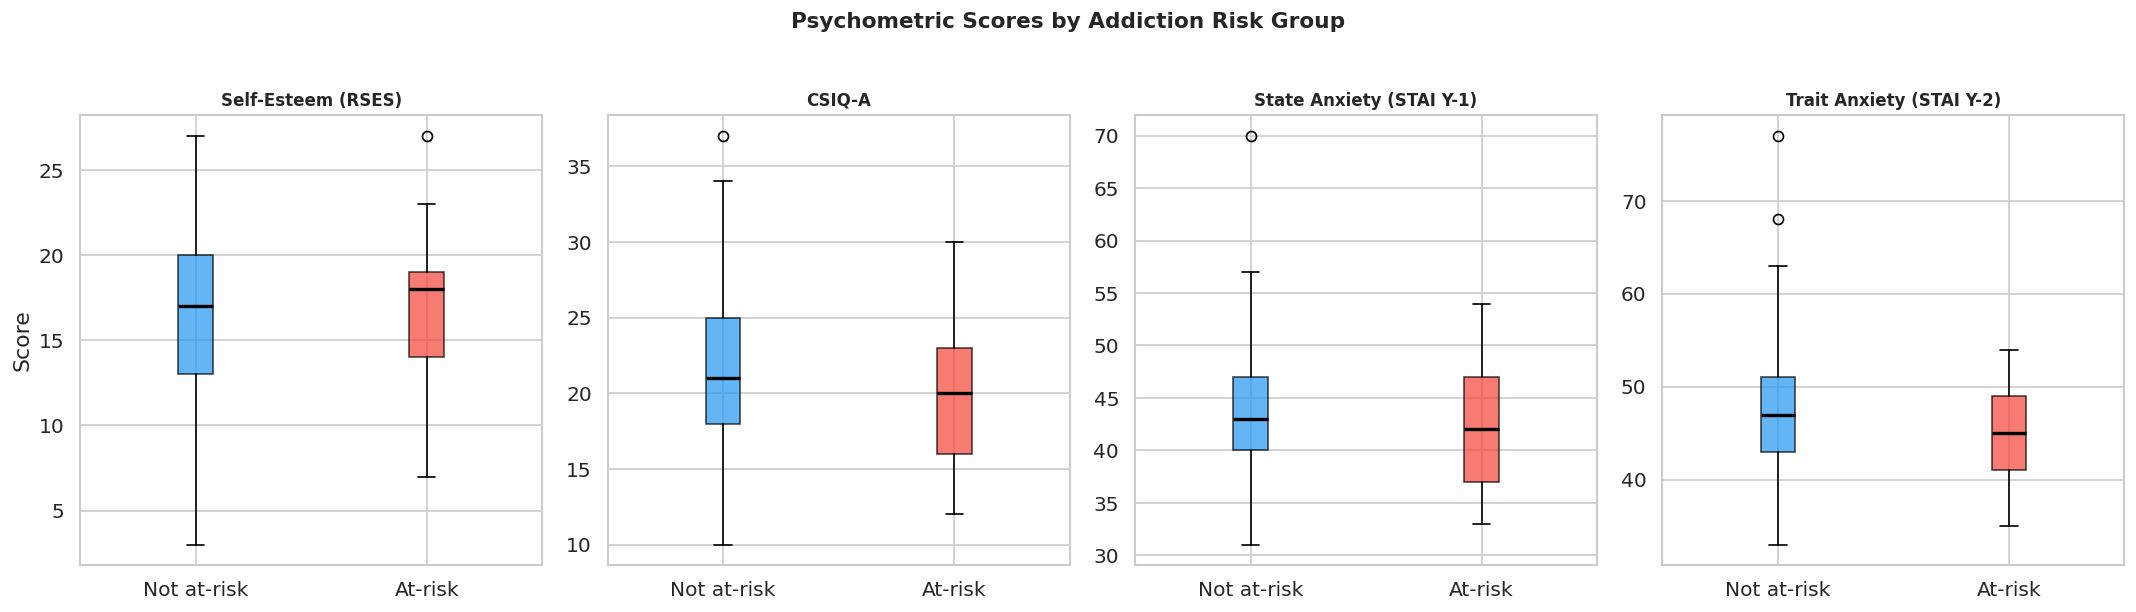

In [ ]:
psych_cols  = ['RSES', 'CSIQ-A', ' STAI Y-1', 'STAI Y-2']
psych_names = ['Self-Esteem (RSES)', 'CSIQ-A', 'State Anxiety (STAI Y-1)', 'Trait Anxiety (STAI Y-2)']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col, name in zip(axes, psych_cols, psych_names):
    data_by_group = [df[df['addiction_risk'] == i][col].values for i in range(2)]
    bp = ax.boxplot(data_by_group, labels=CLASS_NAMES, patch_artist=True,
                     medianprops=dict(color='black', lw=2))
    for patch, color in zip(bp['boxes'], PALETTE):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    ax.set_title(name, fontweight='bold', fontsize=10)
    ax.set_ylabel('Score' if ax is axes[0] else '')

plt.suptitle('Psychometric Scores by Addiction Risk Group', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()


## Correlation with the Binary Target


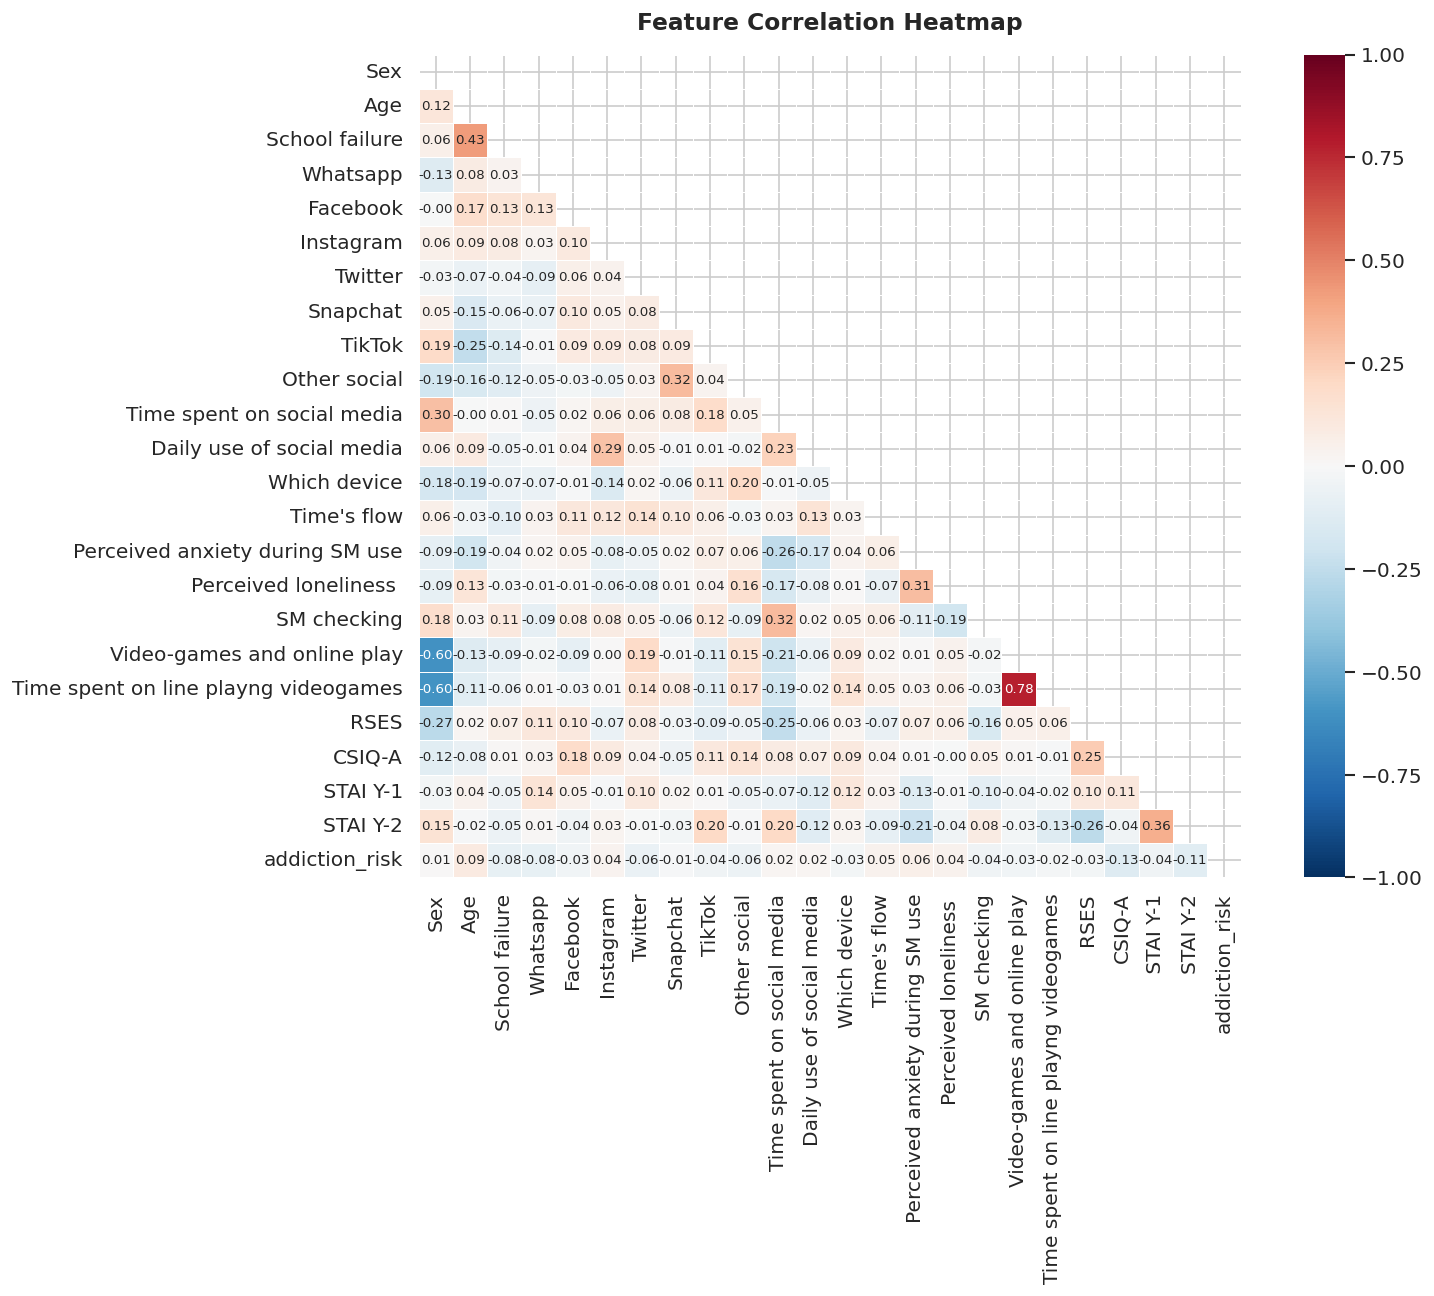


Correlation of each feature with binary addiction_risk:
CSIQ-A                            -0.131787
STAI Y-2                          -0.112803
Age                                0.091184
Whatsapp                          -0.084687
School failure                    -0.082918
Twitter                           -0.063658
Other social                      -0.057271
Perceived anxiety during SM use    0.057117
Time's flow                        0.046106
Perceived loneliness               0.044849


In [ ]:
num_cols_corr = df.select_dtypes(include='number').drop(columns=['BSMAS'], errors='ignore').columns

corr = df[num_cols_corr].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5,
            square=True, ax=ax, annot_kws={'size': 8})
ax.set_title('Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout(); plt.show()

corr_target = df[num_cols_corr].corrwith(df['addiction_risk']).sort_values(key=abs, ascending=False)
print("\nCorrelation of each feature with binary addiction_risk:")
print(corr_target.drop('addiction_risk').head(10).to_string())


## Feature Preparation


In [ ]:
# Based on: scikit-learn, 'Column Transformer with Mixed Types'.
# https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html
# (accessed 21 June 2026).
platform_cols = ['Whatsapp', 'Facebook', 'Instagram', 'Twitter', 'Snapchat', 'TikTok', 'Other social']

df_model = df.drop(columns=['BSMAS']).copy()
df_model['n_platforms'] = df[platform_cols].sum(axis=1)   # simple engineered feature

TARGET = 'addiction_risk'
CATEGORICAL_COLS = ['Sex', 'Which device']
NUMERIC_COLS = [c for c in df_model.columns if c not in CATEGORICAL_COLS + [TARGET]]

X = df_model[NUMERIC_COLS + CATEGORICAL_COLS]
y = df_model[TARGET]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), NUMERIC_COLS),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CATEGORICAL_COLS),
])

print(f"{len(NUMERIC_COLS)} numeric features, {len(CATEGORICAL_COLS)} categorical features (one-hot encoded)")


22 numeric features, 2 categorical features (one-hot encoded)


## Train / Test Split



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape[0]}  Test: {X_test.shape[0]}")
print("Train class balance:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class balance :", y_test.value_counts(normalize=True).round(3).to_dict())


Train: 206  Test: 52
Train class balance: {0: 0.888, 1: 0.112}
Test class balance : {0: 0.885, 1: 0.115}


## Baselines

In [ ]:
# Reference: scikit-learn DummyClassifier documentation.
# https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html
# (accessed 21 June 2026).
baseline_rows = []
for strat in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strat, random_state=SEED)
    dummy.fit(X_train, y_train)
    y_pred = dummy.predict(X_test)
    y_prob = dummy.predict_proba(X_test)[:, 1]
    baseline_rows.append({
        'Strategy': strat,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 (at-risk)': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        'PR-AUC': average_precision_score(y_test, y_prob),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
    })
baseline_df = pd.DataFrame(baseline_rows).set_index('Strategy')
print("Baseline (Dummy) performance:")
baseline_df.round(3)


Baseline (Dummy) performance:


,Accuracy,F1 (at-risk),PR-AUC,ROC-AUC
Strategy,,,,
most_frequent,0.885,0.0,0.115,0.500
stratified,0.769,0.0,0.115,0.435


Any model that does not clearly beat
`most_frequent` on **PR-AUC**, **F1 (at-risk)** and **accuracy** isn't actually adding value.


## Models × Imbalance-Handling Strategies

In [ ]:
# Based on: imbalanced-learn, 'Usage of pipeline embedding samplers'.
# https://imbalanced-learn.org/stable/auto_examples/pipeline/plot_pipeline_classification.html
# Reference: imbalanced-learn SMOTE API.
# https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html
# Reference: GridSearch + Pipelines of Multiple models on Multiclass Classification
# https://ryan-reilly.medium.com/gridsearch-pipelines-of-multiple-models-on-multiclass-classification-e9124b6ea2e3
# (All accessed 24 June 2026).
def make_pipeline(clf, strategy):
    steps = [('preprocess', preprocessor)]
    if strategy == 'smote':

        steps.append(('smote', SMOTE(random_state=SEED, k_neighbors=3)))
    steps.append(('model', clf))
    return Pipeline(steps=steps)

model_specs = {
    'Logistic Regression': lambda cw: LogisticRegression(max_iter=3000, random_state=SEED, class_weight=cw),
    'Decision Tree': lambda cw: DecisionTreeClassifier(random_state=SEED, class_weight=cw),
    'Random Forest': lambda cw: RandomForestClassifier(random_state=SEED, n_jobs=1, class_weight=cw),
    'SVM': lambda cw: SVC(probability=True, random_state=SEED, class_weight=cw),
}

param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l2'],
        'model__solver': ['lbfgs', 'liblinear'],
        'model__class_weight': [None, 'balanced'],
    },
    'Decision Tree': {
        'model__criterion': ['gini', 'entropy'],
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10, 15],
        'model__min_samples_leaf': [1, 2, 4, 6],
        'model__class_weight': [None, 'balanced'],
    },
    'Random Forest': {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_split': [2, 5, 10, 15],
    'model__min_samples_leaf': [1, 2, 4, 6],
    'model__max_features': ['sqrt'],
    'model__class_weight': [None, 'balanced'],
},
    'SVM': {
        'model__C': [0.1, 1, 10, 50, 100],
        'model__kernel': ['linear', 'rbf'],
        'model__gamma': ['scale', 'auto', 0.01, 0.1, 1],
        'model__class_weight': [None, 'balanced'],
    },
}


BALANCE_STRATEGIES = ['none', 'class_weight', 'smote']

combos = []
for model_name in model_specs:
    for strategy in BALANCE_STRATEGIES:
        cw = 'balanced' if strategy == 'class_weight' else None
        clf = model_specs[model_name](cw)
        pipe = make_pipeline(clf, strategy)
        combos.append((model_name, strategy, pipe, param_grids[model_name]))

print(f"Built {len(combos)} (model, balancing) combinations")


Built 12 (model, balancing) combinations


## Nested, Repeated, Stratified Cross-Validation



In [ ]:
# Adapted from: scikit-learn, 'Nested versus non-nested cross-validation'.
# https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html
# Reference: GridSearch + Pipelines of Multiple models on Multiclass Classification
# https://ryan-reilly.medium.com/gridsearch-pipelines-of-multiple-models-on-multiclass-classification-e9124b6ea2e3
# (Both accessed 24 June  2026). This version uses repeated stratified outer folds,
# multiple evaluation metrics, and the study's four classifiers and imbalance strategies.

outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'f1', 'average_precision', 'roc_auc']

nested_rows = []
for model_name, strategy, pipe, grid in combos:
    search = GridSearchCV(pipe, grid, scoring='average_precision', cv=inner_cv, n_jobs=1)
    cv_res = cross_validate(search, X_train, y_train, cv=outer_cv, scoring=scoring, n_jobs=-1)
    nested_rows.append({
        'Model': model_name,
        'Balancing': strategy,
        'Accuracy': cv_res['test_accuracy'].mean(),
        'Accuracy_std': cv_res['test_accuracy'].std(),
        'F1': cv_res['test_f1'].mean(),
        'F1_std': cv_res['test_f1'].std(),
        'PR-AUC': cv_res['test_average_precision'].mean(),
        'PR-AUC_std': cv_res['test_average_precision'].std(),
        'ROC-AUC': cv_res['test_roc_auc'].mean(),
        'ROC-AUC_std': cv_res['test_roc_auc'].std(),
    })
    print(f"done: {model_name:20s} | {strategy:12s} | PR-AUC={nested_rows[-1]['PR-AUC']:.3f}  F1={nested_rows[-1]['F1']:.3f}")

nested_df = pd.DataFrame(nested_rows)


done: Logistic Regression  | none         | PR-AUC=0.176  F1=0.158
done: Logistic Regression  | class_weight | PR-AUC=0.176  F1=0.158
done: Logistic Regression  | smote        | PR-AUC=0.192  F1=0.137
done: Decision Tree        | none         | PR-AUC=0.189  F1=0.215
done: Decision Tree        | class_weight | PR-AUC=0.189  F1=0.215
done: Decision Tree        | smote        | PR-AUC=0.123  F1=0.100


In [ ]:
nested_df_sorted = nested_df.sort_values('PR-AUC', ascending=False).reset_index(drop=True)
n_outer_folds = outer_cv.get_n_splits()
print(f"Nested CV results ({n_outer_folds} outer folds each):")
nested_df_sorted.round(3)


### Top Models by PR-AUC and F1

In [ ]:
print("Top 3 by PR-AUC:")
print(nested_df.sort_values('PR-AUC', ascending=False).head(3)[['Model','Balancing','PR-AUC','F1']].to_string(index=False))
print()
print("Top 3 by F1:")
print(nested_df.sort_values('F1', ascending=False).head(3)[['Model','Balancing','PR-AUC','F1']].to_string(index=False))


## Final Model


In [ ]:
# Based on: scikit-learn, 'Custom refit strategy of a grid search with cross-validation'.
# https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_digits.html
# (accessed 24 June 2026).
SELECTION_METRIC = 'PR-AUC'

best_row = nested_df.sort_values(SELECTION_METRIC, ascending=False).iloc[0]
best_model_name, best_strategy = best_row['Model'], best_row['Balancing']
print(f"Selected by nested-CV {SELECTION_METRIC}: {best_model_name} + {best_strategy}")

best_cw = 'balanced' if best_strategy == 'class_weight' else None
best_clf = model_specs[best_model_name](best_cw)
best_pipe = make_pipeline(best_clf, best_strategy)
best_grid = param_grids[best_model_name]

final_search = GridSearchCV(best_pipe, best_grid, scoring='average_precision', cv=inner_cv, n_jobs=-1)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_
print("Best hyperparameters on full training set:", final_search.best_params_)


In [ ]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("FINAL HELD-OUT TEST SET PERFORMANCE")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}")
print(f"F1       : {f1_score(y_test, y_pred, pos_label=1, zero_division=0):.3f}")
print(f"PR-AUC   : {average_precision_score(y_test, y_prob):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES,
                                          cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name=best_model_name)
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2], name=best_model_name)
axes[2].axhline(y_test.mean(), linestyle='--', color='gray', label='No-skill baseline')
axes[2].set_title('Precision-Recall Curve')
axes[2].legend()

plt.tight_layout()
plt.show()


## SHAP Explainability


In [ ]:
# Based on: SHAP TreeExplainer and generic Explainer API documentation.
# https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html
# https://shap.readthedocs.io/en/latest/generated/shap.Explainer.html
# (both accessed 30 June 2026).
preproc = final_model.named_steps['preprocess']
clf_final = final_model.named_steps['model']
feat_names = preproc.get_feature_names_out()

X_train_t = pd.DataFrame(preproc.transform(X_train), columns=feat_names)
X_test_t = pd.DataFrame(preproc.transform(X_test), columns=feat_names)

if clf_final.__class__.__name__ in ('RandomForestClassifier', 'DecisionTreeClassifier'):
    explainer = shap.TreeExplainer(clf_final)
    shap_values = explainer.shap_values(X_test_t)
    if isinstance(shap_values, list):
        sv = shap_values[1]
    elif np.array(shap_values).ndim == 3:
        sv = np.array(shap_values)[:, :, 1]
    else:
        sv = shap_values
else:
    bg = shap.sample(X_train_t, min(50, len(X_train_t)), random_state=SEED)
    explainer = shap.Explainer(clf_final.predict_proba, bg)
    shap_out = explainer(X_test_t)
    sv = shap_out.values[..., 1] if shap_out.values.ndim == 3 else shap_out.values

mean_abs = np.abs(np.array(sv)).mean(axis=0)
shap_rank = pd.Series(mean_abs, index=feat_names).sort_values(ascending=False)
print("Top 10 features by mean |SHAP value|:")
print(shap_rank.head(10).to_string())


In [ ]:
# Reference: SHAP summary_plot API documentation.
# https://shap.readthedocs.io/en/latest/generated/shap.summary_plot.html
# (accessed 30 June 2026).
shap.summary_plot(sv, X_test_t, plot_type='bar', show=False)
plt.title('Mean |SHAP value| — Feature Importance for At-Risk Prediction', fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
shap.summary_plot(sv, X_test_t, show=False)
plt.title('SHAP Summary (Beeswarm)', fontweight='bold')
plt.tight_layout()
plt.show()